# 01 - Exploration: Spain day-ahead prices (2024)

Goals: load the ENTSO-E data, audit its quality, describe the daily price profile by season,
and relate price to **residual load** (demand - wind - solar).

All series are put on one common grid: **hourly, local time (Europe/Madrid), calendar year 2024**.

## 0. Setup and helpers

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RAW = Path("..") / "data" / "raw"
PROCESSED = Path("..") / "data" / "processed"
FIGURES = Path("..") / "figures"
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

TZ = "Europe/Madrid"
FULL_INDEX = pd.date_range("2024-01-01 00:00", "2024-12-31 23:00", freq="h", tz=TZ)

# Categorical colours in fixed order (blue, orange, aqua, yellow) - see figures
SEASON_ORDER = ["Winter", "Spring", "Summer", "Autumn"]
SEASON_COLORS = {"Winter": "#2a78d6", "Spring": "#eb6834", "Summer": "#1baf7a", "Autumn": "#eda100"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e3e2de"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "text.color": INK, "legend.frameon": False,
})

In [3]:
def read_raw(name, header=0):
    """Read an ENTSO-E CSV; the index becomes a tz-aware UTC DatetimeIndex.

    utc=True is needed because the CSV mixes +01:00 and +02:00 offsets:
    without it pandas cannot build a single datetime column.
    """
    df = pd.read_csv(RAW / name, index_col=0, header=header)
    df.index = pd.to_datetime(df.index, utc=True)
    return df


def to_hourly_local(df, max_gap=3):
    """Hourly mean (MW are averaged, never summed), local time, calendar 2024.

    Missing hours become NaN after resample. If max_gap > 0, they are filled by linear
    interpolation (only for the actual series, which have at most 1 missing hour);
    with max_gap=0 nothing is filled (used for the forecasts, whose long holes must stay NaN).
    """
    out = df.resample("h").mean()
    out.index = out.index.tz_convert(TZ)  #Not necessary with reindex after but I prefer like this
    out = out.reindex(FULL_INDEX)
    return out.interpolate(limit=max_gap) if max_gap else out

## 1. Data checks

### 1.1 Audit of the raw files

In [4]:
FILES = {
    "prices": ("ES_prices.csv", 0),
    "generation": ("ES_generation.csv", [0, 1]),   # two header rows: type / measure
    "load": ("ES_load.csv", 0),
    "load_forecast": ("ES_load_forecast.csv", 0),
    "wind_solar_forecast": ("ES_wind_solar_forecast.csv", 0),
}
raw = {k: read_raw(f, h) for k, (f, h) in FILES.items()}

rows = []
for name, df in raw.items():
    d = df.index.to_series().diff()
    step = d.mode()[0]
    rows.append({
        "file": name,
        "rows": len(df),
        "step": step,
        "first (local)": df.index.min().tz_convert(TZ),
        "last (local)": df.index.max().tz_convert(TZ),
        "missing rows": int(((d[d > step] / step) - 1).sum()),
        "NaN values": int(df.isna().sum().sum()),
        "duplicated stamps": int(df.index.duplicated().sum()),
    })
pd.DataFrame(rows).set_index("file")

,rows,step,first (local),last (local),missing rows,NaN values,duplicated stamps
file,,,,,,,
prices,8784,0 days 01:00:00,2024-01-01 00:00:00+01:00,2025-01-01 00:00:00+01:00,1,0,0
generation,35133,0 days 00:15:00,2024-01-01 00:00:00+01:00,2024-12-31 23:45:00+01:00,3,0,0
load,35135,0 days 00:15:00,2024-01-01 00:00:00+01:00,2024-12-31 23:45:00+01:00,1,0,0
load_forecast,35136,0 days 00:15:00,2024-01-01 00:00:00+01:00,2024-12-31 23:45:00+01:00,0,0,0
wind_solar_forecast,35136,0 days 00:15:00,2024-01-01 00:00:00+01:00,2024-12-31 23:45:00+01:00,0,576,0


Two kinds of holes are possible, and they need different tests:

* **missing rows** (the timestamp does not exist): invisible to `isna()`, found with `index.diff()`;
* **empty values** (the timestamp exists, the value is NaN): found with `isna()`.

In [5]:
# Where exactly are the missing rows? (local time)
for name, df in raw.items():
    d = df.index.to_series().diff()
    step = d.mode()[0]
    for ts, gap in d[d > step].items():
        first_missing = (ts - gap + step).tz_convert(TZ)
        last_missing = (ts - step).tz_convert(TZ)
        print(f"{name:22s} missing {first_missing} -> {last_missing}")

# Where are the empty values? (runs of consecutive NaN rows)
for name, df in raw.items():
    na = df[df.isna().any(axis=1)]
    if na.empty:
        continue
    step = df.index.to_series().diff().mode()[0]
    run_id = (na.index.to_series().diff() != step).cumsum()
    for _, g in na.groupby(run_id.values):
        cols = df.loc[g.index].isna().sum()
        cols = cols[cols > 0].to_dict()
        print(f"{name:22s} NaN {g.index.min().tz_convert(TZ)} -> "
              f"{g.index.max().tz_convert(TZ)}  ({len(g)} rows) {cols}")

prices                 missing 2024-12-31 00:00:00+01:00 -> 2024-12-31 00:00:00+01:00
generation             missing 2024-10-27 02:00:00+02:00 -> 2024-10-27 02:30:00+02:00
load                   missing 2024-10-11 02:30:00+02:00 -> 2024-10-11 02:30:00+02:00
wind_solar_forecast    NaN 2024-06-02 00:00:00+02:00 -> 2024-06-02 23:45:00+02:00  (96 rows) {'Wind Onshore': 96}
wind_solar_forecast    NaN 2024-12-07 00:00:00+01:00 -> 2024-12-11 23:45:00+01:00  (480 rows) {'Solar': 480}


### 1.2 Handling of the holes

| file | hole | treatment |
|---|---|---|
| prices | 1 hour missing (31 Dec 00:00 local) | reindexed, filled by linear interpolation |
| generation | 3 quarter-hours missing (27 Oct, 02:00-02:30, first pass of the repeated 02:00 hour) | the hourly mean uses the remaining quarter-hour |
| load | 1 quarter-hour missing (11 Oct, 02:30) | the hourly mean uses the 3 remaining quarter-hours |
| load forecast | none | - |
| wind/solar forecast | 2 Jun (one column) and 7-11 Dec (the other column) are empty | **left as NaN** (longer than 3 h); handled in the forecasting notebook |

The holes fall on different dates in different files: they come from the source series, not from the download.

### 1.3 Common hourly table

In [6]:
prices = to_hourly_local(raw["prices"])
gen = to_hourly_local(raw["generation"])
load = to_hourly_local(raw["load"])
load_fc = to_hourly_local(raw["load_forecast"], max_gap=0)
ws_fc = to_hourly_local(raw["wind_solar_forecast"], max_gap=0)   # long holes stay NaN

df = pd.DataFrame({
    "price": prices["price_eur_mwh"],                       # EUR/MWh
    "solar": gen[("Solar", "Actual Aggregated")],           # MW, includes thermal solar (see below)
    "wind": gen[("Wind Onshore", "Actual Aggregated")],     # MW (no offshore wind in Spain)
    "load": load["Actual Load"],                            # MW
    "gas_gen": gen[("Fossil Gas", "Actual Aggregated")],    # MW, kept for the gas/carbon block
    "load_fc": load_fc["Forecasted Load"],                  # known before the auction
    "solar_fc": ws_fc["Solar"],
    "wind_fc": ws_fc["Wind Onshore"],
})
df["residual_load"] = df["load"] - df["wind"] - df["solar"]   # MW, realised values
df.index.name = "time_local"
df.shape

(8784, 9)

In [7]:
# Sanity checks on the common table
assert df.index.is_monotonic_increasing and not df.index.duplicated().any()
assert len(df) == 8784

print("NaN per column:")
print(df.isna().sum().to_string())

hours_per_day = df.groupby(df.index.date).size()
print("\nHours per local day:", hours_per_day.value_counts().to_dict())
print("Days != 24 h:", hours_per_day[hours_per_day != 24].to_dict())

print("\nWind offshore max (expected 0):", raw["generation"][("Wind Offshore", "Actual Aggregated")].max())

NaN per column:
price              0
solar              0
wind               0
load               0
gas_gen            0
load_fc            0
solar_fc         120
wind_fc           24
residual_load      0

Hours per local day: {24: 364, 23: 1, 25: 1}
Days != 24 h: {datetime.date(2024, 3, 31): 23, datetime.date(2024, 10, 27): 25}

Wind offshore max (expected 0): 0.0


`Days != 24 h` must show exactly 31 March (23 h) and 27 October (25 h): these are the daylight-saving changes, not errors.

**Solar at night.** The solar column is not exactly zero at night (see the hourly profile below), while its peak is at 13-14 h local, so the time zone is right.
The most likely reason is that ENTSO-E's "Solar" for Spain also includes solar-thermal plants with heat storage; this has not been checked against the source.

In [8]:
# Quick check of the time zone: solar peak hour and night level
solar_by_hour = df.groupby(df.index.hour)["solar"].mean()
print("Solar peak hour (local):", solar_by_hour.idxmax(), "h")
print("Mean solar 00-05 h (MW):", round(solar_by_hour.loc[0:5].mean()))
print("Min hourly solar of the year (MW):", df["solar"].min())

# Forecast quality sanity: the day-ahead forecasts must track the realised values
print("corr solar vs forecast:", round(df["solar"].corr(df["solar_fc"]), 3))
print("corr wind  vs forecast:", round(df["wind"].corr(df["wind_fc"]), 3))
print("load forecast mean abs % error:", round(((df["load"] - df["load_fc"]).abs() / df["load"]).mean() * 100, 2))

Solar peak hour (local): 13 h
Mean solar 00-05 h (MW): 246
Min hourly solar of the year (MW): 4.0
corr solar vs forecast: 0.988
corr wind  vs forecast: 0.952
load forecast mean abs % error: 1.71


### 1.4 Price distribution

count    8784.0
mean       63.0
std        45.9
min        -2.0
25%        17.5
50%        64.8
75%       100.5
max       193.0

Hours with price < 0 : 247   (2.8%)
Hours with price == 0: 537   (6.1%)


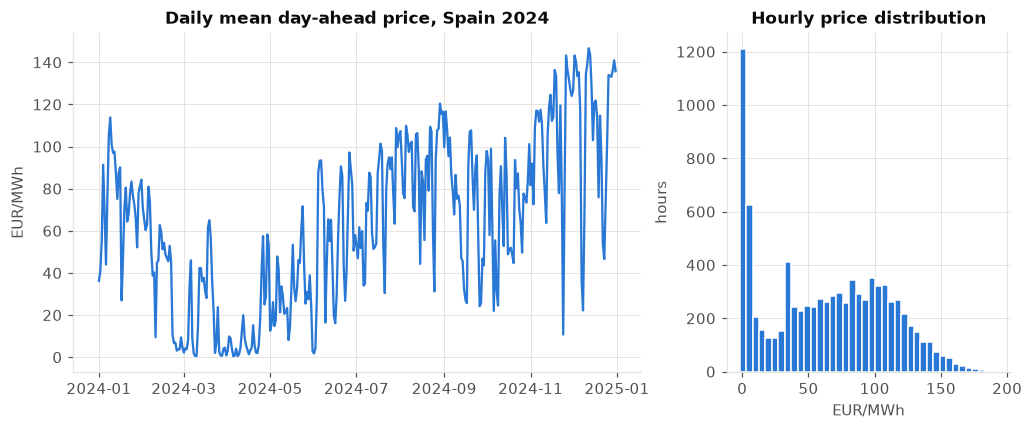

In [23]:
print(df["price"].describe().round(1).to_string())
n_neg, n_zero = int((df.price < 0).sum()), int((df.price == 0).sum())
print(f"\nHours with price < 0 : {n_neg}   ({n_neg / len(df):.1%})")
print(f"Hours with price == 0: {n_zero}   ({n_zero / len(df):.1%})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 1]})
daily = df["price"].resample("D").mean()
ax[0].plot(daily.index, daily.values, color=SEASON_COLORS["Winter"])
ax[0].set_title("Daily mean day-ahead price, Spain 2024")
ax[0].set_ylabel("EUR/MWh")
ax[1].hist(df["price"], bins=40, color=SEASON_COLORS["Winter"], edgecolor="white")
ax[1].set_title("Hourly price distribution")
ax[1].set_xlabel("EUR/MWh")
ax[1].set_ylabel("hours")
fig.savefig(FIGURES / "01_price_overview.png")
plt.show()

## 2. Daily profile by season

Local time matters here: "12 h" must mean the same moment of the day all year long, which is why the index is converted to Europe/Madrid.
Seasons are meteorological (Winter = Dec-Feb, Spring = Mar-May, Summer = Jun-Aug, Autumn = Sep-Nov).

In [33]:
SEASON_OF_MONTH = {1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                   6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn", 12: "Winter",}
df["hour"] = df.index.hour
df["month"] = df.index.month
df["season"] = pd.Categorical(df["month"].map(SEASON_OF_MONTH), categories=SEASON_ORDER, ordered=True)

profile = df.groupby(["season", "hour"])["price"].mean().unstack(0)
profile.round(1).iloc[[0, 3, 6, 9, 12, 14, 18, 21]]

season,Winter,Spring,Summer,Autumn
hour,,,,
0,74.6,29.3,95.3,88.0
3,61.5,22.5,85.7,74.8
6,69.8,27.8,90.5,85.2
9,83.8,17.1,70.1,90.5
12,60.9,6.0,42.4,53.6
14,59.7,4.1,39.3,48.7
18,96.2,13.3,55.0,94.4
21,97.5,50.3,114.6,117.1


        hours  hours <= 0  share
season                          
Winter   2184          34   1.6%
Spring   2207         507  23.0%
Summer   2208         171   7.7%
Autumn   2185          72   3.3%


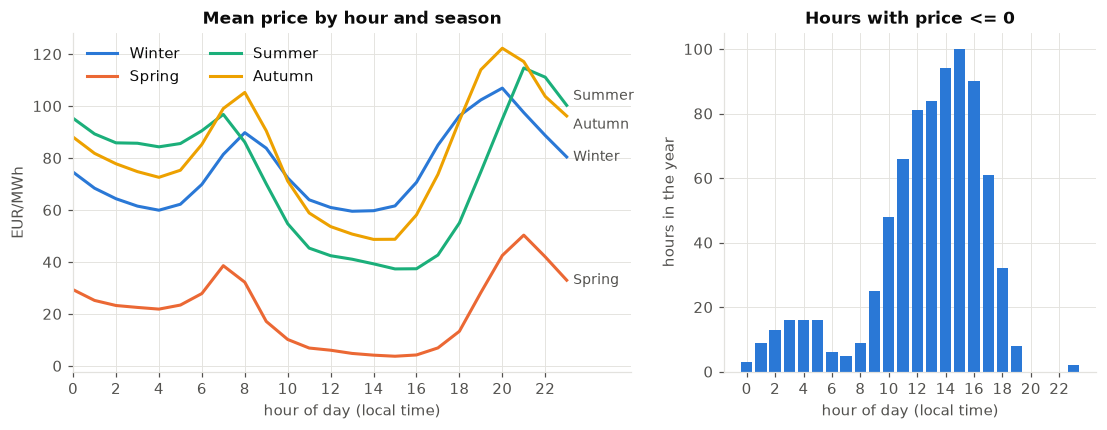

In [43]:
nonpos = df[df["price"] <= 0]
by_season = pd.DataFrame({
    "hours": df.groupby("season", observed=True).size(),
    "hours <= 0": nonpos.groupby("season", observed=True).size(),
}).fillna(0).astype(int)
by_season["share"] = (by_season["hours <= 0"] / by_season["hours"]).map("{:.1%}".format)
print(by_season.to_string())

by_hour = nonpos.groupby("hour").size().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 2]})
NUDGE = {"Summer": 3.5, "Autumn": -3.5}      # avoid overlapping end labels
for s in SEASON_ORDER:
    ax[0].plot(profile.index, profile[s], color=SEASON_COLORS[s], lw=2, label=s)
    ax[0].text(23.3, profile[s].iloc[-1] + NUDGE.get(s, 0), s, color=INK_2, va="center", fontsize=9)
ax[0].set_xlim(0, 26)
ax[0].set_xticks(range(0, 24, 2))
ax[0].set_xlabel("hour of day (local time)")
ax[0].set_ylabel("EUR/MWh")
ax[0].set_title("Mean price by hour and season")
ax[0].legend(loc="upper left", ncol=2)

ax[1].bar(by_hour.index, by_hour.values, color=SEASON_COLORS["Winter"], width=0.8)
ax[1].set_xticks(range(0, 24, 2))
ax[1].set_xlabel("hour of day (local time)")
ax[1].set_ylabel("hours in the year")
ax[1].set_title("Hours with price <= 0")
fig.savefig(FIGURES / "01_profile_by_season.png")
plt.show()

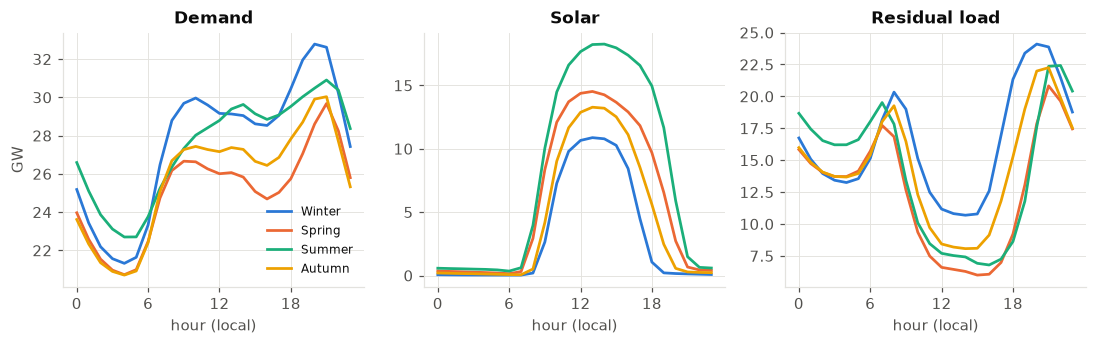

In [50]:
# What shapes the profile: demand, solar and residual load by hour and season
fig, ax = plt.subplots(1, 3, figsize=(12, 3), sharex=True)
for a, col, title in zip(ax, ["load", "solar", "residual_load"],
                         ["Demand", "Solar", "Residual load"]):
    p = df.groupby(["season", "hour"], observed=True)[col].mean().unstack(0) / 1000
    for s in SEASON_ORDER:
        a.plot(p.index, p[s], color=SEASON_COLORS[s], lw=1.8, label=s)
    a.set_title(title)
    a.set_xticks(range(0, 24, 6))
    a.set_xlabel("hour (local)")
ax[0].set_ylabel("GW")
ax[0].legend(loc="lower right", fontsize=8)
fig.savefig(FIGURES / "01_drivers_by_season.png")
plt.show()

### What the profile shows

* **Two-peak shape in every season**: a morning peak around 7-8 h and an evening peak around 20-21 h, with a trough in the middle of the day.
* **The midday trough is a solar effect**. It is deepest in spring (mean price about 4 EUR/MWh at 14-15 h, against about 60 in winter) and goes together with the lowest residual load of the day (right-hand panel of the drivers figure).
* **The evening is where solar is gone and demand is still high**: residual load climbs to 20-24 GW around 21 h and so does the price.
* **Evening minus midday mean price** (20-22 h vs 12-15 h): +67 EUR/MWh in summer, +64 in autumn, +40 in spring, +37 in winter.
* **Non-positive prices**: 784 hours (8.9 % of the year), of which 65 % in spring and 80 % between 10:00 and 17:59. A smaller cluster appears between 0 and 5 h (possibly low demand and wind, not tested). The minimum price of the year is only -2 EUR/MWh, so "negative" hours are barely negative: most of them are exactly 0.

## 3. Residual load vs price

`residual load = demand - wind - solar` (realised values, MW): the demand that dispatchable plants (gas, hydro, coal, imports) must cover.
In a merit-order market, the more residual load there is, the further up the cost curve the marginal plant sits, and the higher the price.

Linear fit: price = -9.6 + 5.06 * residual_load[GW]
R2 = 0.53   correlation = 0.73   n = 8784


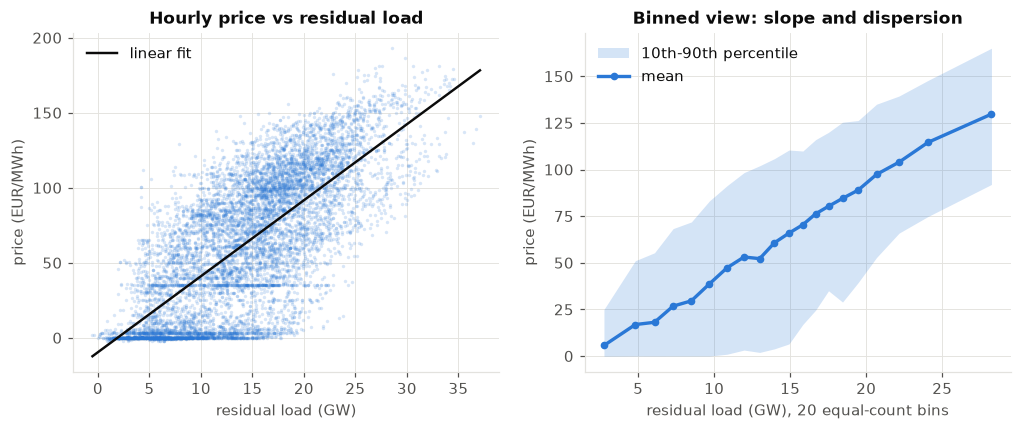

In [49]:
x = df["residual_load"].copy() / 1000      # GW
y = df["price"].copy()

fit = stats.linregress(x, y)
print(f"Linear fit: price = {fit.intercept:.1f} + {fit.slope:.2f} * residual_load[GW]")
print(f"R2 = {fit.rvalue**2:.2f}   correlation = {fit.rvalue:.2f}   n = {len(df)}")

# Binned view: 20 equal-count bins of residual load
bins = pd.qcut(x, 20)
b = pd.DataFrame({"rl": x, "price": y, "bin": bins}).groupby("bin").agg(
    rl=("rl", "mean"), mean=("price", "mean"),
    p10=("price", lambda s: s.quantile(0.10)), p90=("price", lambda s: s.quantile(0.90)))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(x, y, s=5, alpha=0.18, color=SEASON_COLORS["Winter"], linewidths=0)
xx = np.array([x.min(), x.max()])
ax[0].plot(xx, fit.intercept + fit.slope * xx, color=INK, lw=1.6, label="linear fit")
ax[0].set_xlabel("residual load (GW)")
ax[0].set_ylabel("price (EUR/MWh)")
ax[0].set_title("Hourly price vs residual load")
ax[0].legend(loc="upper left")

ax[1].fill_between(b["rl"], b["p10"], b["p90"], color=SEASON_COLORS["Winter"], alpha=0.2, linewidth=0,
                   label="10th-90th percentile")
ax[1].plot(b["rl"], b["mean"], color=SEASON_COLORS["Winter"], lw=2.2, marker="o", ms=4, label="mean")
ax[1].set_xlabel("residual load (GW), 20 equal-count bins")
ax[1].set_ylabel("price (EUR/MWh)")
ax[1].set_title("Binned view: slope and dispersion")
ax[1].legend(loc="upper left")
fig.savefig(FIGURES / "01_price_vs_residual_load.png")
plt.show()

In [14]:
# Same relation by season (slope in EUR/MWh per GW, and correlation)
rows = []
for s in SEASON_ORDER:
    d = df[df["season"] == s]
    f = stats.linregress(d["residual_load"] / 1000, d["price"])
    rows.append({"season": s, "slope EUR/MWh per GW": round(f.slope, 2), "R2": round(f.rvalue**2, 2),
                 "mean price": round(d["price"].mean(), 1), "mean residual load GW": round(d["residual_load"].mean() / 1000, 1)})
pd.DataFrame(rows).set_index("season")

,slope EUR/MWh per GW,R2,mean price,mean residual load GW
season,,,,
Winter,4.37,0.52,75.9,16.3
Spring,3.24,0.51,21.5,12.6
Summer,5.45,0.74,73.3,14.0
Autumn,5.75,0.73,81.7,14.5


In [15]:
# Price level in a few residual-load regimes
regime = pd.cut(x, [-1, 5, 10, 15, 20, 40], labels=["< 5 GW", "5-10", "10-15", "15-20", "> 20"])
pd.DataFrame({"price": y, "regime": regime}).groupby("regime", observed=True)["price"].agg(
    hours="size", mean="mean", median="median").round(1)

,hours,mean,median
regime,,,
< 5 GW,710,10.4,0.4
5-10,1821,26.3,14.0
10-15,2125,54.3,56.0
15-20,2362,78.9,86.0
> 20,1766,111.3,114.8


### Reading the relation

* **Slope**: about +5 EUR/MWh per additional GW of residual load; the linear fit has R2 = 0.53, i.e. residual load alone explains about half of the variance of hourly prices.
* **Merit-order reading**: with little residual load (< 5 GW) the median price is about 0 (wind, solar and other low-marginal-cost sources set the price); above 20 GW the mean is about 111 EUR/MWh, where gas-fired plants are typically on the margin. The binned mean rises almost steadily between the two.
* **Dispersion is large**: between 10 and 13 GW the 10th percentile is close to 0 and the 90th close to 100 EUR/MWh. The same residual load can come with very different prices, so other drivers matter (gas and carbon costs, hydro availability, interconnections, season). This is what the next notebooks look at.
* **Two flat clusters are visible**: about 940 hours at roughly 0 EUR/MWh, and about 300 hours at roughly 35 EUR/MWh, mostly between March and June and at all hours of the day. A constant price that does not follow residual load suggests a block of supply offered at that price (hydro is a plausible candidate in spring), but this has not been tested here.
* **By season**, the slope ranges from 3.2 (spring) to 5.8 EUR/MWh per GW (autumn), and spring prices are much lower at comparable residual load.

*Caveats*: this is a correlation on realised values, not a causal estimate; residual load as defined ignores imports/exports and pumping.

## 4. Findings

In [16]:
# 1) Non-positive prices
h_le0 = int((df.price <= 0).sum())
top_season = by_season["hours <= 0"].idxmax()
share_in_season = by_season.loc[top_season, "hours <= 0"] / h_le0
mid = nonpos[(nonpos.hour >= 10) & (nonpos.hour <= 17)]
print(f"1) {h_le0} hours with price <= 0 ({h_le0 / len(df):.1%} of the year); "
      f"{share_in_season:.0%} of them in {top_season}; {len(mid) / h_le0:.0%} between 10:00 and 17:59.")

# 2) Midday vs evening price, season by season
midday = df[df.hour.between(12, 15)].groupby("season", observed=True)["price"].mean()
evening = df[df.hour.between(20, 22)].groupby("season", observed=True)["price"].mean()
gap = (evening - midday).round(1)
print("2) Evening (20-22 h) minus midday (12-15 h) mean price, EUR/MWh:", gap.to_dict())
print(f"   largest in {gap.idxmax()}: {midday[gap.idxmax()]:.1f} at midday vs {evening[gap.idxmax()]:.1f} in the evening.")

# 3) Price vs residual load
print(f"3) Each additional GW of residual load adds about {fit.slope:.1f} EUR/MWh; "
      f"correlation {fit.rvalue:.2f} (R2 = {fit.rvalue**2:.2f}).")

1) 784 hours with price <= 0 (8.9% of the year); 65% of them in Spring; 80% between 10:00 and 17:59.
2) Evening (20-22 h) minus midday (12-15 h) mean price, EUR/MWh: {'Winter': 37.3, 'Spring': 40.3, 'Summer': 66.9, 'Autumn': 63.9}
   largest in Summer: 40.0 at midday vs 106.9 in the evening.
3) Each additional GW of residual load adds about 5.1 EUR/MWh; correlation 0.73 (R2 = 0.53).


1. **784 hours (8.9 %) at a price of 0 or below in 2024**: 65 % of them in spring and 80 % between 10:00 and 17:59, i.e. when solar output is high.
2. **Summer evening vs midday**: mean price of about 107 EUR/MWh at 20-22 h against 40 at 12-15 h, a spread of about 67 EUR/MWh created by the disappearance of solar.
3. **About +5 EUR/MWh per GW of residual load** (correlation 0.73, R2 = 0.53): residual load explains roughly half of the hourly price variance; the rest is left to gas, carbon, hydro and interconnections.

## 5. Save the clean table

In [17]:
cols = ["price", "solar", "wind", "load", "residual_load", "gas_gen", "load_fc", "solar_fc", "wind_fc"]
df[cols].to_parquet(PROCESSED / "ES_hourly_2024.parquet")
print("saved", (PROCESSED / "ES_hourly_2024.parquet").name, df[cols].shape)

saved ES_hourly_2024.parquet (8784, 9)
